# Steam tag network: which two-tag concept should an indie studio build next?
MADT 7202 mid-term · evidence notebook. Every number on the one-page report is written to
`outputs/numbers.json` by this notebook. Rules live in `src/tagnet.py`.

**Decision:** which two-tag game concept the creative director of an indie studio builds next.

**Sources:** S1 = FronkonGames Steam Games Dataset (MIT): every game in the cohort, with tag votes and review
totals. This is the data the network is built from. S2 = live Steam store pull for a random 1,000 of those games
(tags from the app page, review totals from `appreviews`), used to check that S1 is accurate.
SteamSpy was also pulled but mirrors S1 exactly (shown below), so it is not an independent source.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import tagnet as tn

OUT = ROOT / "outputs"
(OUT / "tables").mkdir(parents=True, exist_ok=True)
NUM = {}  # every number used on the page
pd.set_option("display.width", 160)

cohort = tn.load_cohort()                      # S1: all games, the analysis set
games = tn.load_games()                        # S2: live pull for the random 1,000, the cross-check set
games = games[games["s2_tags"].map(len) > 0].reset_index(drop=True)
NUM.update(population=len(cohort), sampled=1000, analysed=len(games),
           fetched_from=games["fetched"].min()[:10], fetched_to=games["fetched"].max()[:10],
           median_reviews=float(cohort["reviews"].median()))
print(NUM)

{'population': 9094, 'sampled': 1000, 'analysed': 996, 'fetched_from': '2026-10-14', 'fetched_to': '2026-10-14', 'median_reviews': 40.0}


## 1 · Is S1 accurate? Compare it with the live store (S2) on the random 1,000

In [2]:
def jacc(a, b):
    a, b = set(a), set(b)
    return len(a & b) / len(a | b) if a | b else np.nan

def top5(d):
    return [t for t in d if t not in tn.SEED_TAGS][:5]

j5 = [jacc(top5(a), top5(b)) for a, b in zip(games["s1_tags"], games["s2_tags"])]
rho = spearmanr(games["reviews"], games["s2_reviews"]).statistic
ss = games["ss_tags"].notna()
j5_ss = [jacc(top5(a), top5(b)) for a, b in zip(games.loc[ss, "s1_tags"], games.loc[ss, "ss_tags"])]
NUM.update(tri_top5_jaccard=float(np.nanmean(j5)), tri_top5_identical=float(np.mean(np.array(j5) == 1)),
           tri_reviews_spearman=float(rho),
           review_growth=float(games["s2_reviews"].sum() / games["reviews"].sum()),
           steamspy_vs_s1_jaccard=float(np.nanmean(j5_ss)),
           steamspy_vs_s1_reviews_equal=float((games.loc[ss, "ss_reviews"] == games.loc[ss, "reviews"]).mean()))
print({k: round(NUM[k], 3) for k in ["tri_top5_jaccard", "tri_top5_identical", "tri_reviews_spearman",
                                     "review_growth", "steamspy_vs_s1_jaccard", "steamspy_vs_s1_reviews_equal"]})

{'tri_top5_jaccard': 0.869, 'tri_top5_identical': 0.711, 'tri_reviews_spearman': 0.977, 'review_growth': 1.254, 'steamspy_vs_s1_jaccard': 1.0, 'steamspy_vs_s1_reviews_equal': 1.0}


## 2 · The seed and generic-tag trap
"Indie" is the collection seed. Tags in > 25 % of games are generic (rule fixed in advance).

In [3]:
dicts = list(cohort["tags"])
reviews = cohort["reviews"].values
tag_lists = [list(d) for d in dicts]
indie_share = np.mean(["Indie" in t for t in tag_lists])
generic, dfreq = tn.generic_tags(tag_lists, tn.DEFAULTS["generic_df"])
gen_table = pd.Series(dfreq).sort_values(ascending=False).head(20).rename("doc_freq").to_frame()
gen_table["generic"] = gen_table.index.isin(generic)
NUM.update(indie_share=float(indie_share), generic=sorted(generic, key=lambda t: -dfreq[t]),
           n_generic=len(generic))
gen_table.round(3)

,doc_freq,generic
Singleplayer,0.753,True
Adventure,0.464,True
Action,0.434,True
Casual,0.425,True
2D,0.401,True
3D,0.345,True
Atmospheric,0.287,True
Exploration,0.283,True
Simulation,0.248,False
First-Person,0.238,False


## 3 · Graph construction
K = 5 tags per game; tag on ≥ 1.5 % of games; edge NPMI ≥ 0.10 and ≥ 0.5 % shared games.
(Thresholds are shares of the games analysed, so they mean the same thing at 1,000 or 9,094 games.)

In [4]:
R = tn.run(dicts, reviews)
G, pairs, P = R["G"], R["pairs"], R["params"]
n_tags_raw = len({t for d in dicts for t in d})
NUM.update(nodes=G.number_of_nodes(), edges=G.number_of_edges(), tags_before=n_tags_raw,
           min_tag=P["min_tag"], min_co=P["min_co"], min_pair=P["min_pair"])
print(f"{n_tags_raw} distinct tags before pruning -> {G.number_of_nodes()} nodes, {G.number_of_edges()} edges", P)

439 distinct tags before pruning -> 80 nodes, 177 edges {'k': 5, 'generic_df': 0.25, 'min_tag': 136, 'npmi_cut': 0.1, 'min_co': 45, 'min_pair': 73, 'max_sat': 1.5, 'max_overlap': 0.2}


### Named alternative (a): raw co-occurrence count instead of NPMI
Raw count is computed on the *uncleaned* top-5 tags (what a naive build sees).

In [5]:
naive = [[t for t in tags if t not in tn.SEED_TAGS][:5] for tags in tag_lists]
n_a, n_ab = tn.cooccurrence(naive)
top5_common = [t for t, _ in n_a.most_common(5)]
raw_top = sorted(n_ab.items(), key=lambda kv: (-kv[1], kv[0]))[:10]
raw_touch = sum(a in top5_common or b in top5_common for (a, b), _ in raw_top)
npmi_top = sorted(G.edges(data=True), key=lambda e: (-e[2]["npmi"], e[0], e[1]))[:10]
npmi_touch = sum(a in top5_common or b in top5_common for a, b, _ in npmi_top)
NUM.update(top5_common=top5_common, raw_top10_touch_common=raw_touch, npmi_top10_touch_common=npmi_touch,
           raw_top_edge=list(raw_top[0][0]), raw_top_edge_count=raw_top[0][1])
print("5 most common tags:", top5_common)
print("raw-count top-10 edges:", raw_top)
print("NPMI top-10 edges:", [(a, b, round(d["npmi"], 2)) for a, b, d in npmi_top])

5 most common tags: ['Adventure', 'Casual', 'Action', 'Puzzle', 'Simulation']
raw-count top-10 edges: [(('Action', 'Adventure'), 528), (('Casual', 'Simulation'), 419), (('Horror', 'Psychological Horror'), 411), (('Adventure', 'Casual'), 392), (('Casual', 'Puzzle'), 388), (('Action', 'Casual'), 337), (('Adventure', 'Puzzle'), 329), (('Adventure', 'RPG'), 306), (('Adventure', 'Exploration'), 277), (('Action', 'Action-Adventure'), 272)]
NPMI top-10 edges: [('Clicker', 'Idler', np.float64(0.6)), ('Card Game', 'Deckbuilding', np.float64(0.6)), ('Action Roguelike', 'Bullet Hell', np.float64(0.6)), ('Turn-Based Strategy', 'Turn-Based Tactics', np.float64(0.6)), ('Horror', 'Psychological Horror', np.float64(0.59)), ('2D Platformer', 'Platformer', np.float64(0.57)), ('Action Roguelike', 'Rogue-lite', np.float64(0.56)), ('FPS', 'Shooter', np.float64(0.51)), ('Horror', 'Survival Horror', np.float64(0.5)), ('Visual Novel', 'Dating Sim', np.float64(0.49))]


## 4 · Pairs: which combinations perform, and which are already crowded?
A pair is eligible if it is not over-supplied (≤ 1.5× the games chance predicts) and its two tags sit in
separate neighbourhoods (neighbour overlap ≤ 0.2). Eligible pairs are ranked by lift (median reviews ÷ cohort).

In [6]:
pairs.to_csv(OUT / "tables/pairs.csv", index=False)
elig = pairs[pairs["eligible"]].reset_index(drop=True)
print(len(pairs), "scored pairs;", len(elig), "eligible")
elig.head(10).round(2)

135 scored pairs; 32 eligible


,a,b,n_ab,expected,saturation,median_reviews,lift,hit_rate,overlap,npmi,eligible
0,First-Person,Multiplayer,78,70.72,1.10,204.0,5.10,0.37,0.08,0.02,True
1,Horror,Multiplayer,114,92.70,1.23,117.0,2.92,0.23,0.08,0.05,True
2,Pixel Graphics,RPG,133,106.78,1.25,70.0,1.75,0.13,0.00,0.05,True
3,RPG,Story Rich,98,76.62,1.28,61.0,1.52,0.15,0.06,0.05,True
4,Horror,Story Rich,102,79.46,1.28,60.5,1.51,0.12,0.14,0.06,True
5,Relaxing,Simulation,78,59.68,1.31,56.5,1.41,0.13,0.00,0.06,True
6,RPG,Strategy,128,122.47,1.05,55.0,1.38,0.13,0.05,0.01,True
7,Pixel Graphics,Rogue-lite,77,60.82,1.27,55.0,1.38,0.14,0.15,0.05,True
8,Puzzle,Story Rich,105,100.38,1.05,53.0,1.32,0.13,0.13,0.01,True
9,RPG,Rogue-lite,73,76.62,0.95,49.0,1.23,0.15,0.05,-0.01,True


In [7]:
# Crowded comparison: best pair that passes the overlap rule but fails only the crowding rule
crowded = pairs[(pairs["saturation"] > P["max_sat"]) & (pairs["overlap"] <= P["max_overlap"])].reset_index(drop=True)
top10 = pairs.head(10)
NUM.update(top10_lift_crowded=int((top10["saturation"] > P["max_sat"]).sum()))
print("of the 10 highest-lift pairs,", NUM["top10_lift_crowded"], "are over-supplied")
crowded.head(5).round(2)

of the 10 highest-lift pairs, 8 are over-supplied


,a,b,n_ab,expected,saturation,median_reviews,lift,hit_rate,overlap,npmi,eligible
0,Building,Simulation,74,29.14,2.54,136.5,3.41,0.28,0.08,0.19,False
1,Management,Simulation,121,31.81,3.80,127.0,3.18,0.23,0.08,0.31,False
2,Anime,RPG,111,48.77,2.28,84.0,2.10,0.09,0.07,0.19,False
3,Female Protagonist,RPG,77,48.77,1.58,83.0,2.08,0.08,0.14,0.10,False
4,Life Sim,Simulation,156,33.64,4.64,82.5,2.06,0.12,0.00,0.38,False


### Why the play-mode tags are merged (resolution), and what the winning pair is made of

In [8]:
raw_b = tn.run(dicts, reviews, resolve_tags=False)["baskets"]   # same pipeline, tags as Steam lists them
COOP = {"Co-op", "Online Co-Op", "Local Co-Op", "Co-op Campaign"}
hm = [i for i, b in enumerate(raw_b) if {"Horror", "Multiplayer"} <= set(b)]
NUM.update(unmerged_hm_n=len(hm), unmerged_hm_coop=int(sum(bool(COOP & set(dicts[i])) for i in hm)))
HORROR = {"Horror", "Psychological Horror", "Survival Horror"}
e0 = (elig.loc[0, "a"], elig.loc[0, "b"])
pick_games = [i for i, b in enumerate(R["baskets"]) if set(e0) <= set(b)]
NUM.update(pick_horror=int(sum(bool(HORROR & set(tn.resolve(dicts[i]))) for i in pick_games)),
           pick_top_game=cohort.loc[max(pick_games, key=lambda i: reviews[i]), "name"],
           third=[elig.loc[2, "a"], elig.loc[2, "b"]])
print(f"before merging, {NUM['unmerged_hm_coop']}/{NUM['unmerged_hm_n']} Horror x Multiplayer games also carry a co-op tag;",
      f"{NUM['pick_horror']}/{len(pick_games)} of the pick's games are horror (top: {NUM['pick_top_game']}); #3 = {NUM['third']}")

before merging, 63/75 Horror x Multiplayer games also carry a co-op tag; 53/78 of the pick's games are horror (top: Lethal Company); #3 = ['Pixel Graphics', 'RPG']


## 5 · Robustness

In [9]:
def rank_of(pair, pairs_df):
    e = pairs_df[pairs_df["eligible"]].reset_index(drop=True)
    for i, r in enumerate(e.itertuples(), 1):
        if tuple(sorted((r.a, r.b))) == pair:
            return i
    return None

best = tuple(sorted((elig.loc[0, "a"], elig.loc[0, "b"])))
runner = tuple(sorted((elig.loc[1, "a"], elig.loc[1, "b"])))
sweep = []
for cut in [0.05, 0.10, 0.15, 0.20]:
    for mc in [0.005, 0.01]:
        sweep.append({"param": f"NPMI>={cut}, co>={mc:.1%}",
                      "rank": rank_of(best, tn.run(dicts, reviews, npmi_cut=cut, min_co=mc)["pairs"])})
for k in [3, 5, 10, 20]:
    sweep.append({"param": f"K={k}", "rank": rank_of(best, tn.run(dicts, reviews, k=k)["pairs"])})
for gdf in [0.20, 0.25, 0.35]:
    sweep.append({"param": f"generic>{gdf:.0%}", "rank": rank_of(best, tn.run(dicts, reviews, generic_df=gdf)["pairs"])})
for mp in [0.006, 0.008, 0.010]:
    sweep.append({"param": f"pair>={mp:.1%}", "rank": rank_of(best, tn.run(dicts, reviews, min_pair=mp)["pairs"])})
sweep = pd.DataFrame(sweep)
p20 = tn.run(dicts, reviews, k=20)["pairs"]
r20 = p20[(p20.a.isin(best)) & (p20.b.isin(best))].iloc[0]
NUM.update(k20_n=int(r20.n_ab), k20_lift=float(r20.lift), k20_sat=float(r20.saturation))
sweep.to_csv(OUT / "tables/robustness_sweep.csv", index=False)
sweep

,param,rank
0,"NPMI>=0.05, co>=0.5%",1.0
1,"NPMI>=0.05, co>=1.0%",1.0
2,"NPMI>=0.1, co>=0.5%",1.0
3,"NPMI>=0.1, co>=1.0%",1.0
4,"NPMI>=0.15, co>=0.5%",1.0
5,"NPMI>=0.15, co>=1.0%",1.0
6,"NPMI>=0.2, co>=0.5%",1.0
7,"NPMI>=0.2, co>=1.0%",1.0
8,K=3,NaN
9,K=5,1.0


In [10]:
# Second source: the pair's lift on the live-scraped sample (S2 tags and live review counts)
s2_base = tn.run(list(games["s2_tags"]), games["s2_reviews"].values)["baskets"]
s2_rev = games["s2_reviews"].values
s2_has = np.array([set(best) <= set(b) for b in s2_base])
NUM.update(s2_pair_n=int(s2_has.sum()), s2_pair_lift=float(np.median(s2_rev[s2_has]) / np.median(s2_rev)))
print("S2 sample:", NUM["s2_pair_n"], "games with the pair, lift", round(NUM["s2_pair_lift"], 2))

S2 sample: 0 games with the pair, lift nan


/Users/pollot/Documents/kg-midterm/.venv/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/pollot/Documents/kg-midterm/.venv/lib/python3.12/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [11]:
# Bootstrap: resample games. Rank = is the pair still the top eligible pair? Lift = the pair's games' median
# reviews / cohort median. Saturation = does the pair cross the 1.5x crowding limit in the resample?
rng = np.random.default_rng(7202)
has_pair = np.array([set(best) <= set(b) for b in R["baskets"]])
boot_rank, boot_lift, boot_sat, boot_planb = [], [], [], []
for _ in range(100):
    i = rng.integers(0, len(cohort), len(cohort))
    pr = tn.run([dicts[j] for j in i], reviews[i])["pairs"]
    boot_rank.append(rank_of(best, pr))
    boot_planb.append(rank_of(runner, pr))
    row = pr[(pr.a == best[0]) & (pr.b == best[1])]
    boot_sat.append(float(row["saturation"].iloc[0]) if len(row) else np.nan)
    r_i, h_i = reviews[i], has_pair[i]
    boot_lift.append(np.median(r_i[h_i]) / np.median(r_i) if h_i.any() else np.nan)
boot_rank, boot_planb = pd.Series(boot_rank, dtype="float"), pd.Series(boot_planb, dtype="float")
boot_lift, boot_sat = np.array(boot_lift), np.array(boot_sat)
# why the pair is not #1 in a resample: below the support floor (not scored), over the crowding limit, or outranked
NUM.update(boot_below_floor=int(np.isnan(boot_sat).sum()),
           boot_outranked=int(((boot_rank > 1) | (boot_rank.isna() & ~np.isnan(boot_sat) & (boot_sat <= P["max_sat"]))).sum()),
           boot_planb_top1=int((boot_planb == 1).sum()), boot_either_top1=int(((boot_rank == 1) | (boot_planb == 1)).sum()))
NUM.update(boot_top1=int((boot_rank == 1).sum()), boot_top3=int((boot_rank <= 3).sum()),
           boot_lift_gt1=int((boot_lift > 1).sum()), boot_sat_over=int((boot_sat > P["max_sat"]).sum()),
           boot_lift_p05=float(np.nanpercentile(boot_lift, 5)), boot_lift_p95=float(np.nanpercentile(boot_lift, 95)))
print({k: NUM[k] for k in ["boot_top1", "boot_top3", "boot_lift_gt1", "boot_sat_over", "boot_below_floor",
                            "boot_outranked", "boot_planb_top1", "boot_either_top1", "boot_lift_p05", "boot_lift_p95"]})

{'boot_top1': 59, 'boot_top3': 74, 'boot_lift_gt1': 100, 'boot_sat_over': 0, 'boot_below_floor': 24, 'boot_outranked': 17, 'boot_planb_top1': 35, 'boot_either_top1': 94, 'boot_lift_p05': 2.3246036585365855, 'boot_lift_p95': 9.901646341463413}


In [12]:
# Permutation test: how often do n random games from the cohort reach the pair's median reviews?
b0 = elig.loc[0]
draws = np.array([np.median(rng.choice(reviews, int(b0.n_ab), replace=False)) for _ in range(10000)])
NUM.update(perm_p=float((draws >= b0.median_reviews).mean()), perm_draws=len(draws))
print("permutation p =", NUM["perm_p"])

permutation p = 0.0


## 6 · Record the headline numbers

In [13]:
def rec(r):
    return dict(pair=[r.a, r.b], n=int(r.n_ab), expected=float(r.expected), sat=float(r.saturation),
                overlap=float(r.overlap), median=float(r.median_reviews), lift=float(r.lift), hit=float(r.hit_rate),
                npmi=float(r.npmi), edge=bool(G.has_edge(r.a, r.b)))

b = elig.loc[0]
NUM.update(best=list(best), runner=list(runner), pick=rec(b), planb=rec(elig.loc[1]), crowd=rec(crowded.loc[0]),
           hit_cut=float(np.quantile(reviews, 0.9)),
           sweep=sweep.to_dict("records"), eligible=len(elig), scored_pairs=len(pairs))
(OUT / "numbers.json").write_text(json.dumps(NUM, indent=2, default=str))
pd.DataFrame([NUM["pick"], NUM["planb"], NUM["crowd"]]).round(2)

,pair,n,expected,sat,overlap,median,lift,hit,npmi,edge
0,"[First-Person, Multiplayer]",78,70.72,1.10,0.08,204.0,5.10,0.37,0.02,False
1,"[Horror, Multiplayer]",114,92.70,1.23,0.08,117.0,2.92,0.23,0.05,False
2,"[Building, Simulation]",74,29.14,2.54,0.08,136.5,3.41,0.28,0.19,True


## 7 · The figure: the neighbourhoods of the recommended pair and plan B
Node colour = median reviews of games with the tag. Labels are placed only where they touch no other label,
node or edge; the cell fails if that is impossible.

layout, rotation, flip: (0, 0, 1) labels on an edge: 0 worst label ratio: 0.66


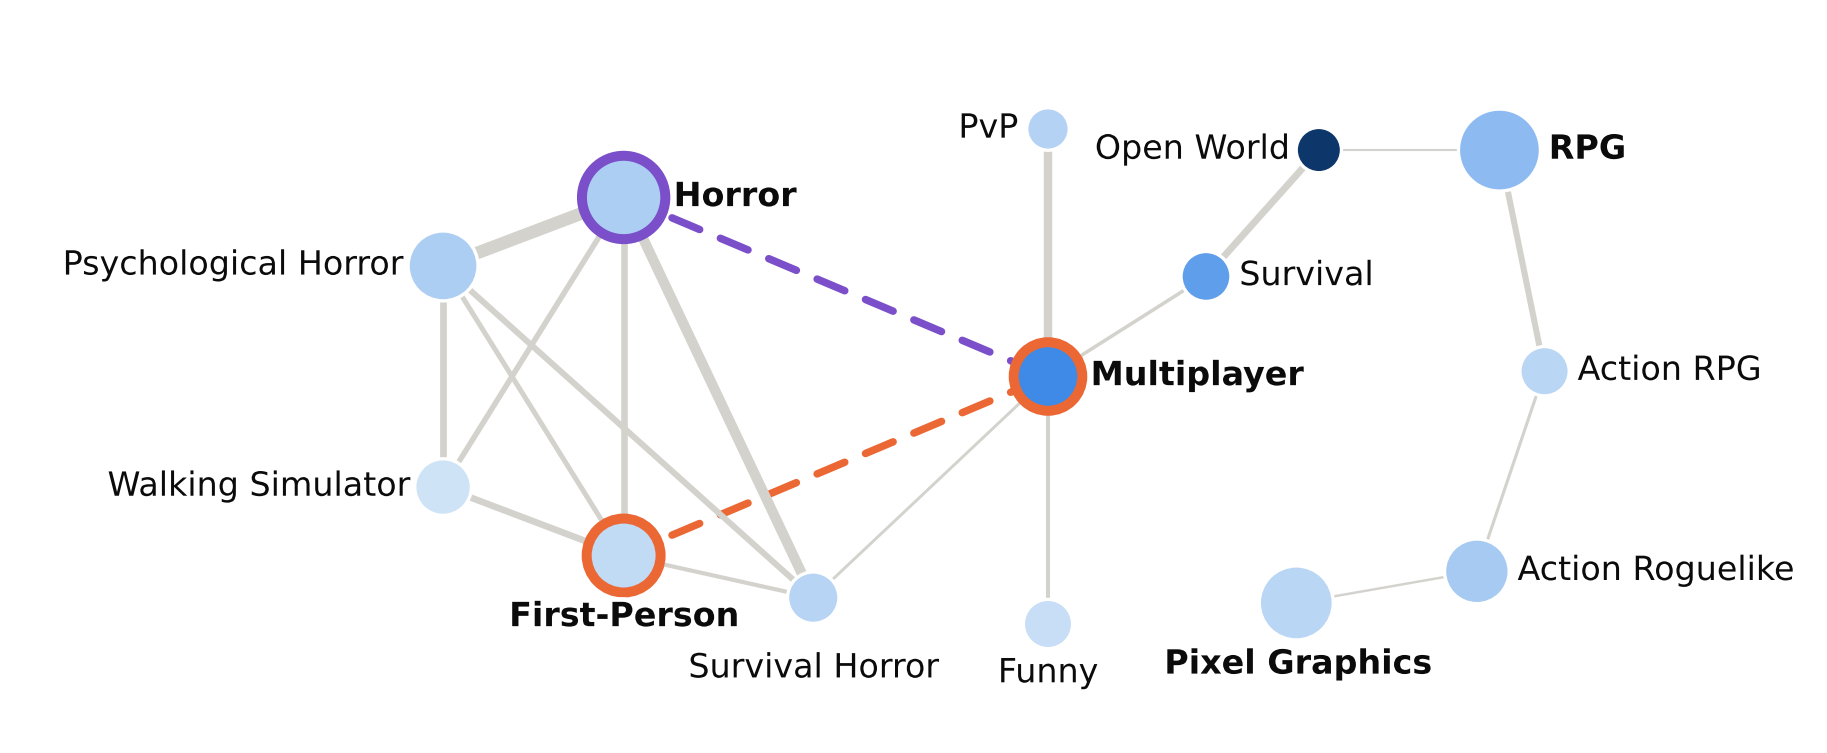

In [14]:
import matplotlib.patheffects as pe
from matplotlib.patches import FancyArrowPatch
from matplotlib.colors import LinearSegmentedColormap, LogNorm

INK, EDGE, ACCENT, PLANB = "#0b0b0b", "#d3d2cc", "#eb6834", "#7a4fc9"
BLUES = LinearSegmentedColormap.from_list("seq", ["#cfe3f7", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
HALO = [pe.withStroke(linewidth=2.2, foreground="white")]

tag_med = {t: float(np.median(reviews[[t in bk for bk in R["baskets"]]])) for t in G}
third = tuple(sorted(NUM["third"]))  # the #3 pair (fallback in section 8): its tags are shown for context
focus = set(best) | set(runner) | set(third)
# the pick's and plan B's tags with their 2 strongest neighbours (by NPMI), plus the shortest paths linking the pairs
show = set(focus)
for t in sorted(set(best) | set(runner)):  # the #3 pair is shown with its linking path only, to keep the picture light
    show |= set(sorted(G[t], key=lambda u: (-G[t][u]["npmi"], u))[:2])
for u, v in [best, runner, third, (best[1], third[1])]:
    show |= set(nx.shortest_path(G, u, v, weight="dist"))
H = G.subgraph(show).copy()
assert nx.is_connected(H)
# rebuild in sorted order: subgraph views iterate a Python set, which would make the layout hash-seed dependent
H2 = nx.Graph()
H2.add_nodes_from((t, G.nodes[t]) for t in sorted(H))
H2.add_edges_from(sorted((*sorted((u, v)), d) for u, v, d in H.edges(data=True)))
H = H2
# hand-designed layout (x, y): the horror tags as a convex quadrilateral (so no edge passes under a node), Survival
# Horror below on the First-Person - Multiplayer path, Multiplayer in the middle with the two dashed pairs fanning out, the #3 pair's chain curving round on the
# right. If the graph ever changes and a tag is missing here, fall back to an automatic Kamada-Kawai search.
MANUAL = {"Survival Horror": (1.08, 0.03), "First-Person": (0.66, 0.11), "Walking Simulator": (0.26, 0.24),
          "Psychological Horror": (0.26, 0.66), "Horror": (0.66, 0.79),
          "Multiplayer": (1.6, 0.45), "PvP": (1.6, 0.92), "Funny": (1.6, -0.02),
          "Survival": (1.95, 0.64), "Open World": (2.2, 0.88), "RPG": (2.6, 0.88), "Action RPG": (2.7, 0.46),
          "Action Roguelike": (2.55, 0.08), "Pixel Graphics": (2.15, 0.02)}
LABEL_SIDE = {"Survival Horror": "below"}  # labels tried on this side first (the rest use the default order)
if set(H) <= set(MANUAL):
    layouts, views = [{t: np.array(MANUAL[t]) for t in H}], [(0, 1)]
else:
    layouts = [nx.kamada_kawai_layout(H, weight=None)] + [
        nx.kamada_kawai_layout(H, weight=None, pos=nx.spring_layout(H, seed=sd)) for sd in range(1, 41)]
    views = [(a, f) for f in (1, -1) for a in range(0, 180, 15)]
nmax = max(H.nodes[t]["n"] for t in H)
sizes = {t: 40 + 360 * H.nodes[t]["n"] / nmax for t in H}
norm = LogNorm(vmin=min(tag_med[t] for t in H), vmax=max(tag_med[t] for t in H))
ring = {t: PLANB for t in runner} | {t: ACCENT for t in best}  # a tag in both pairs keeps the pick's colour
pk = NUM["pick"]
msg = (f"{best[0]} × {best[1]}{'' if pk['edge'] else ': near chance, no edge'}\n"
       f"{pk['n']} games (exp. {pk['expected']:.0f}) · {pk['lift']:.1f}× median reviews")


def hit(a, c, pad=2):
    return not (a[2] + pad < c[0] or c[2] + pad < a[0] or a[3] + pad < c[1] or c[3] + pad < a[1])


def inside_pts(pts, box):
    return ((pts[:, 0] > box[0] + 1) & (pts[:, 0] < box[2] - 1) & (pts[:, 1] > box[1] + 1) & (pts[:, 1] < box[3] - 1)).any()


def draw(kk, angle, flip):
    """Draw the graph with the layout rotated/flipped; place labels where they touch no label, node or edge.
    Returns the figure and the number of labels that could only be placed on top of an edge."""
    th = np.radians(angle)
    rot = np.array([[np.cos(th), -np.sin(th)], [np.sin(th), np.cos(th)]])
    xy = np.array([kk[t] for t in H]) @ rot.T * [flip, 1]
    # stretch to the figure's wide frame; nodes that this flattens onto an edge are nudged off it below
    xy = (xy - xy.min(0)) / (xy.max(0) - xy.min(0))
    pos = {t: (x * 2.4, y) for t, (x, y) in zip(H, xy)}

    fig, ax = plt.subplots(figsize=(7.6, 3.0), dpi=300)
    ax.set_xlim(-0.9, 2.95); ax.set_ylim(-0.2, 1.2); ax.axis("off")  # margins leave room for labels at the edges
    # tight clusters (tags that are almost all linked to each other) can't be drawn flat without one node landing
    # on another pair's edge: nudge such nodes sideways off the edge, and keep nodes from overlapping
    px0, inv0 = ax.transData.transform, ax.transData.inverted().transform
    P = {t: np.array(px0(pos[t]), dtype=float) for t in H}
    rad = {t: np.sqrt(sizes[t]) / 2 * fig.dpi / 72 for t in H}
    for _ in range(300):
        moved = False
        for u, v in H.edges():
            a_, d_ = P[u], P[v] - P[u]
            for w in H:
                if w in (u, v):
                    continue
                q = a_ + np.clip(np.dot(P[w] - a_, d_) / np.dot(d_, d_), 0, 1) * d_
                gap, need = np.linalg.norm(P[w] - q), rad[w] + 15 + 3
                if gap < need:
                    n_ = (P[w] - q) / gap if gap > 1e-6 else np.array([-d_[1], d_[0]]) / np.linalg.norm(d_)
                    P[w] = P[w] + n_ * (need - gap)
                    moved = True
        for u in H:
            for w in H:
                if u < w and np.linalg.norm(P[u] - P[w]) < rad[u] + rad[w] + 10:
                    n_ = (P[w] - P[u]) / max(np.linalg.norm(P[w] - P[u]), 1e-6)
                    push = (rad[u] + rad[w] + 10 - np.linalg.norm(P[w] - P[u])) / 2
                    P[u], P[w] = P[u] - n_ * push, P[w] + n_ * push
                    moved = True
        if not moved:
            break
    pos = {t: tuple(inv0(P[t])) for t in H}
    nx.draw_networkx_edges(H, pos, ax=ax, width=[0.3 + 6.0 * d["npmi"] ** 1.5 for _, _, d in H.edges(data=True)],
                           edge_color=EDGE)
    nx.draw_networkx_nodes(H, pos, ax=ax, nodelist=list(H), node_size=[sizes[t] for t in H],
                           node_color=[tag_med[t] for t in H], cmap=BLUES, vmin=norm.vmin, vmax=norm.vmax,
                           linewidths=[2.4 if t in ring else 0.8 for t in H],
                           edgecolors=[ring.get(t, "white") for t in H])
    pairs_drawn = [(best, ACCENT), (runner, PLANB)]
    fig.canvas.draw()
    rend = fig.canvas.get_renderer()
    frame = ax.get_window_extent(rend)
    px = ax.transData.transform
    nodes = {}
    for t in H:
        r = np.sqrt(sizes[t]) / 2 * fig.dpi / 72
        cx, cy = px(pos[t])
        nodes[t] = (cx - r, cy - r, cx + r, cy + r)
    def clear_of_nodes(pts, ends, pad=15):
        """True if no point of the line comes within a node (plus 15 px at 300 dpi) other than its two ends."""
        return all(np.hypot(*(pts - px(pos[w])).T).min() >= (nodes[w][2] - nodes[w][0]) / 2 + pad
                   for w in H if w not in ends)

    # real edges are straight and may not pass under another node (it would look as if that node sat on the edge)
    edge_pts = [px(np.linspace(pos[u], pos[v], 40)) for u, v in H.edges()]
    if not all(clear_of_nodes(p, e) for p, e in zip(edge_pts, H.edges())):
        return fig, 99, 9.0
    # the recommended pair and plan B have no edge: draw them dashed, bending (arc3) around any node in the way
    pair_mid, drawn_pairs = {}, []
    shared = set(best) & set(runner)

    def apart(pts, q):
        keep = np.ones(len(pts), bool)
        for x in shared:
            keep &= np.hypot(*(pts - px(pos[x])).T) > 150
        if not keep.any():
            return True
        diff = pts[keep][:, None, :] - q[None, :, :]
        return np.hypot(diff[..., 0], diff[..., 1]).min() >= 30
    for (u, v), col in pairs_drawn:
        a, b2 = px(pos[u]), px(pos[v])
        for rad in (0, 0.2, -0.2, 0.35, -0.35, 0.5, -0.5, 0.65, -0.65, 0.8, -0.8):
            ctrl = (a + b2) / 2 + rad * np.array([b2[1] - a[1], a[0] - b2[0]])  # matplotlib's arc3 control point
            s_ = np.linspace(0, 1, 60)[:, None]
            pts = (1 - s_) ** 2 * a + 2 * (1 - s_) * s_ * ctrl + s_ ** 2 * b2
            # the two dashed curves must stay apart, except close to a tag they share
            if clear_of_nodes(pts, (u, v), pad=12) and all(apart(pts, q) for q in drawn_pairs[:0]):
                break
        else:
            return fig, 99, 9.0
        ax.add_patch(FancyArrowPatch(pos[u], pos[v], connectionstyle=f"arc3,rad={rad}", arrowstyle="-",
                                     linestyle=(0, (4, 3)), color=col, lw=1.8, zorder=0.5, shrinkA=0, shrinkB=0))
        edge_pts.append(pts)
        drawn_pairs.append(pts)
        pair_mid[(u, v)] = ax.transData.inverted().transform(pts[30])
    edge_px = np.vstack(edge_pts)
    # the edges that link each pair (shortest paths) carry the story: no label may sit on them, even as a fallback
    key = {frozenset(e) for u, v in (best, runner, third) for e in nx.utils.pairwise(nx.shortest_path(H, u, v))}
    key_px = np.vstack([p_ for p_, e in zip(edge_pts, H.edges()) if frozenset(e) in key] + drawn_pairs)

    # the colour key is drawn on the page (report/template.html), from NUM['colour_lo'] / NUM['colour_hi']
    placed = {}

    def box_dist(box, w):
        cx, cy = px(pos[w])
        return np.hypot(max(box[0] - cx, 0, cx - box[2]), max(box[1] - cy, 0, cy - box[3]))

    def free(box, own=None, edges=True):
        # a label must sit clearly nearer its own node than any other node, or it reads as the wrong tag's label
        if own is not None and any(box_dist(box, own) > 0.8 * box_dist(box, w) for w in H if w != own):
            return False
        return (box[0] >= frame.x0 and box[2] <= frame.x1 and box[1] >= frame.y0 and box[3] <= frame.y1
                and not any(hit(box, o, 15) for o in placed.values())  # 15 px gap: stacked labels read as one
                and not any(hit(box, nb, 0) for u, nb in nodes.items() if u != own)
                and not inside_pts(key_px, box)
                and not (edges and inside_pts(edge_px, box)))

    on_edge, worst = 0, 0.0  # worst = the most ambiguous label: own-node distance / nearest other node
    for t in sorted(H, key=lambda t: (t not in focus, -H.nodes[t]["n"], t)):
        r = np.sqrt(sizes[t]) / 2 + 2  # points
        cands = [c for k in (1, 1.6) for c in [(k * r, 0, "left", "center"), (-k * r, 0, "right", "center"), (0, k * r, "center", "bottom"),
                 (0, -k * r, "center", "top"), (k * r * .7, k * r * .7, "left", "bottom"),
                 (-k * r * .7, k * r * .7, "right", "bottom"), (k * r * .7, -k * r * .7, "left", "top"),
                 (-k * r * .7, -k * r * .7, "right", "top")]]  # next to the node first, then a little further out
        side = {"right": 0, "left": 1, "above": 2, "below": 3}.get(LABEL_SIDE.get(t))
        if side is not None:
            cands = [cands[side], cands[side + 8]] + cands
        done = False
        for edges in (True, False):  # prefer a spot clear of edges; never accept one on a label or node
            for dx, dy, ha, va in cands:
                txt = ax.annotate(t, pos[t], xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                                  fontsize=8.0, color=INK, fontweight="bold" if t in focus else "normal",
                                  path_effects=HALO)
                e = txt.get_window_extent(rend)
                if free((e.x0, e.y0, e.x1, e.y1), own=t, edges=edges):
                    placed[t] = (e.x0, e.y0, e.x1, e.y1)
                    worst = max(worst, box_dist(placed[t], t) / min(box_dist(placed[t], w) for w in H if w != t))
                    done = True
                    on_edge += not edges
                    break
                txt.remove()
            if done:
                break
        if not done:
            return fig, 99, 9.0

    # pair call-outs are written on the page (report/template.html), placed by hand for the clearest layout
    return fig, on_edge, worst


# try each layout in 12 rotations x 2 reflections. Hard rules: no edge passes under another node, no label covers
# a label or node. Of the drawings that pass, keep the one with the fewest labels resting on an edge, then the clearest.
chosen, best_worst, fig = None, None, None
for li, kk in enumerate(layouts):
    for angle, flip in views:
        f_, bad, worst = draw(kk, angle, flip)
        # bad = labels that could only sit on an edge (99 = a hard rule failed); fewest first, then clearest
        if bad < 99 and (best_worst is None or (bad, worst) < best_worst):
            if fig is not None:
                plt.close(fig)
            chosen, best_worst, fig = (li, angle, flip), (bad, worst), f_
        else:
            plt.close(f_)
assert chosen, "no layout gives clear labels and clear edges"
print("layout, rotation, flip:", chosen, "labels on an edge:", best_worst[0], "worst label ratio:", round(best_worst[1], 2))
fig.savefig(OUT / "fig_network.png", dpi=300, bbox_inches="tight", facecolor="white")
fig.savefig(OUT / "fig_network.svg", bbox_inches="tight", facecolor="white")
NUM.update(fig_nodes=H.number_of_nodes(), fig_edges=H.number_of_edges(), colour_lo=float(norm.vmin), colour_hi=float(norm.vmax))
(OUT / "numbers.json").write_text(json.dumps(NUM, indent=2, default=str))
plt.show()

## 8 · Sanity checks (fail loudly)

In [15]:
assert "Indie" not in G, "seed tag leaked into the graph"
assert not (set(G) & set(NUM["generic"])), "generic tag leaked into the graph"
assert not (set(G) & tn.NON_DESIGN), "non-design tag leaked into the graph"
assert "Indie" not in best and not (set(best) & set(NUM["generic"])), "recommended pair is an artifact"
assert NUM["nodes"] == G.number_of_nodes() and NUM["edges"] == G.number_of_edges()
assert NUM["analysed"] >= 950, "too many games missing live data"
assert NUM["population"] > 9000, "cohort incomplete"
assert NUM["steamspy_vs_s1_jaccard"] > 0.99 and NUM["tri_top5_jaccard"] < 0.99, "S2 should differ from S1, SteamSpy should not"
assert best != runner
print("all checks passed")

all checks passed
